# Lecture 1: Basic Financial Calculations



## 1.0 Quick review: a dollar today is not a dollar tomorrow

Every topic in this course — bonds, portfolios, simulations — rests on one idea: **cash at different points in time is not the same thing**, and to compare or combine cash flows we must move them to the same point in time. Moving a future cash flow back to today is called **discounting**; the result is its **present value (PV)**.

The present value of a cash flow $CF_t$ received at time $t$ is

$$PV = \frac{CF_t}{(1+r)^t}$$

The discount rate $r$ is the **opportunity cost** of money: the return you could earn on a comparable alternative investment. The riskier the cash flow, the higher the $r$ you demand, and the less the promise is worth today. Synonyms you will meet constantly: discount rate, cost of capital, interest rate, required return.

That is the entire theory for today. The rest of the lecture is one question asked over and over, on increasingly interesting problems: *what is this stream of future payments worth right now?*

>  **Question:** *You can have €100 today or €120 in three years. What single number do you need to know before you can decide?*

---
## 1.1 The best real-estate deal in history?

In 1803 the United States bought the Louisiana Territory from Napoleon's France: 2.1 million km$^2$ — a quarter of today's continental US — for \$15 million. France needed cash for war; the US paid largely with bonds, sold on to Barings in London and Hope & Co. in Amsterdam. Everyone calls it the best deal ever made. Was it?

### Discussion:

Suppose that instead of buying land, the US had invested the \$15 million in 1803 and earned a steady return for 223 years. At 5\% per year, how much would it have today? (a) $≈$ \$3 billion (b) $≈$ \$50 billion (c) $≈$ \$800 billion (d) $≈$ \$50 trillion

Second: at 7\% instead — about what stock markets have returned over the long run — which answer?

In [1]:
# One cash flow: 15 million dollars, invested in 1803
amount = 15e6
T = 2026 - 1803

r = 0.05
FV = amount * (1 + r)**T
print(f"Return {r:.0%}:  $15M in 1803 grows to ${FV/1e9:,.0f} billion today")

r = 0.07
FV = amount * (1 + r)**T
print(f"Return {r:.0%}:  $15M in 1803 grows to ${FV/1e9:,.0f} billion today")


Return 5%:  $15M in 1803 grows to $797 billion today
Return 7%:  $15M in 1803 grows to $53,539 billion today


### Investigate

At 3% the \$15 million grows to about **\$11 billion** — a mid-sized company. At 7% it grows to **\$54 trillion**, nearly twice the entire US economy. Same \$15 million, same 223 years: the *only* thing that changed is the rate, and the answer moved by a factor of five thousand.

It also means "was it a good deal?" has no answer until you say what the money *could* have earned instead. That opportunity cost is what a discount rate is, and it is the first input in every model in this course.

### Practice

US GDP today is roughly **\$30 trillion**. Using the code above, find (by trial and error) the return at which \$15 million in 1803 would have grown to exactly \$30 trillion. Is it closer to 5%, 6.7%, or 8%?


In [2]:
# solution


---
## 1.2 Present values, step by step

 **Investment 1** pays €100 at the end of each of the next five years. Cash flows are risk-free. A bank pays 4% on a 5-year deposit — so 4% is our opportunity cost.

### Discussion

Five payments of €100 should add up to €500 "on paper".

Will the present value be **(a)** exactly 500 **(b)** a bit below 500 **(c)** a bit above 500? And *why*?

In [3]:
CF1 = 100; CF2 = 100; CF3 = 100; CF4 = 100; CF5 = 100   # ";" separates expressions on one line
r = 0.04

PV0 = CF1/(1+r)**1 + CF2/(1+r)**2 + CF3/(1+r)**3 + CF4/(1+r)**4 + CF5/(1+r)**5
print("The present value of Investment 1 is", PV0)

# a cleaner way to print: an f-string with 2 decimal places
print(f"The present value of Investment 1 is {PV0:.2f} Euro")

The present value of Investment 1 is 445.1822331016205
The present value of Investment 1 is 445.18 Euro



**Investment 2** promises 100 in year 1, 200 in year 2, 300 in year 3, 400 in year 4, and 500 in year 5 — €1,500 "on paper".

### Discussion

Investment 2 pays €1,500 in total; three times the €500 of Investment 1. Is its present value **more or less than three times** Investment 1's?

*(Hint: where in time do Investment 2's cash flows arrive, compared to Investment 1's?)*

In [4]:
CF1 = 100; CF2 = 200; CF3 = 300; CF4 = 400; CF5 = 500
r = 0.04
PV0 = CF1/(1+r)**1 + CF2/(1+r)**2 + CF3/(1+r)**3 + CF4/(1+r)**4 + CF5/(1+r)**5
print(f"The present value of Investment 2 is {PV0:.2f} Euro")

The present value of Investment 2 is 1300.65 Euro


<details>
<summary> <b>Solution</b></summary>

Less than three times (1300.65 < 3 $\times$ 445.18 = 1335.55). Investment 2's cash is *back-loaded* — the biggest payments come latest, and late money is discounted hardest. Same total, different timing, different value: this is the whole point of discounting.

</details>



### Net Present Value

Suppose Investment 2 is offered to you **for €1,500**. Given that its cash flows are worth only €1,300.65, buying it destroys value. The **Net Present Value (NPV)** makes this a single number by including the (negative) time-0 cash flow:

$$NPV = CF_0 +\sum\limits_{t=1}^N\frac{CF_t}{(1+r)^t}$$

Decision rule: **take the project if NPV > 0.**

In [5]:
CF0 = -1500
CF1 = 100; CF2 = 200; CF3 = 300; CF4 = 400; CF5 = 500
r = 0.04
NPV = CF0 + CF1/(1+r)**1 + CF2/(1+r)**2 + CF3/(1+r)**3 + CF4/(1+r)**4 + CF5/(1+r)**5
print(f"The NPV of buying Investment 2 for 1500 Euro is {NPV:.2f} Euro")

The NPV of buying Investment 2 for 1500 Euro is -199.35 Euro


### Practice

You are offered an asset costing €600 that pays €100 at the end of each of the next 10 years. The appropriate discount rate is 8%. Should you buy it?

Write the code yourself.


<details>
<summary> <b>Solution</b></summary>

```python
payment = 100
r = 0.08
n = 10
price = 600

# present value of a finite annuity
PV0 = payment * (1 - 1/(1+r)**n) / r
print(f"PV = {PV0:.2f}, NPV = {PV0 - price:.2f}")

if PV0 - price > 0:
    print("Buy the asset!")
else:
    print("Don't buy the asset!")
```

PV $\approx$ €671 > €600, so NPV $\approx$ +€71: buy.

</details>

In [6]:
# solution


---
## 1.3 IRR: the rate hiding inside a deal

Flip the question. Instead of "given a rate, what is the value?", ask: **"given the price, what rate am I actually being offered?"** The **internal rate of return (IRR)** is the discount rate that makes the NPV exactly zero:

$$CF_0 +\sum\limits_{t=1}^N\frac{CF_t}{(1+IRR)^t} = 0$$

This is the number to pull out whenever someone quotes you money-later-for-money-now: a bank, a car dealer, or a pension provider. Suppose the cash flows of Investment 2 cost €800 today.

### Discussion

At €1,500 the deal was bad, and at its fair value €1,300.65 the NPV is zero — meaning at a €1,300.65 price the IRR would be exactly 4%. At a price of €800, is the IRR **higher or lower** than 4%? Ballpark it: 6%? 15%? 25%?

There is no clean solution for IRR (it is the root of a 5th-degree polynomial). Let's use Python's `fsolve` to find it numerically:

In [7]:
from scipy.optimize import fsolve
CF1 = 100; CF2 = 200; CF3 = 300; CF4 = 400; CF5 = 500
CF0 = -800

IRR = fsolve(lambda IRR: CF0 + CF1/(1+IRR)**1 + CF2/(1+IRR)**2 \
             + CF3/(1+IRR)**3 + CF4/(1+IRR)**4 + CF5/(1+IRR)**5, 0.05)
print(f"The IRR of buying Investment 2 for 800 Euro is {100*IRR[0]:.2f}%")

NPV = CF0 + CF1/(1+IRR)**1 + CF2/(1+IRR)**2 \
             + CF3/(1+IRR)**3 + CF4/(1+IRR)**4 + CF5/(1+IRR)**5
print(f"Checking that NPV is zero: NPV = {NPV[0]:.10f}")

The IRR of buying Investment 2 for 800 Euro is 19.54%
Checking that NPV is zero: NPV = -0.0000000000


### Model: NPV as a function of the discount rate

**Discussion:** the curve below plots NPV against the discount rate. Before running — does it slope up or down? Where does it cross zero?

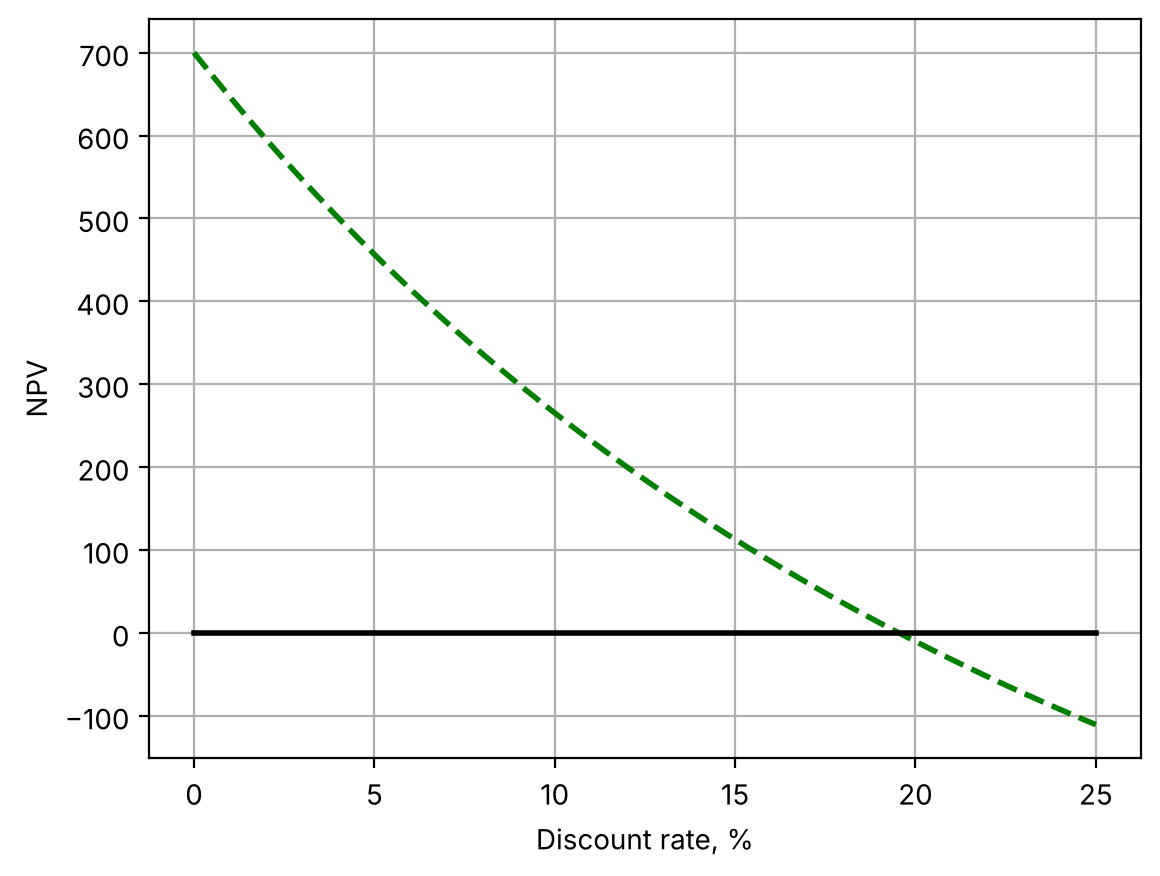

In [8]:
import matplotlib.pyplot as plt
import numpy as np
CF1 = 100; CF2 = 200; CF3 = 300; CF4 = 400; CF5 = 500
CF0 = -800

i = np.linspace(0, 0.25, 100)   # 100 equally spaced rates between 0% and 25%
npv = CF0 + CF1/(1+i)**1 + CF2/(1+i)**2 + CF3/(1+i)**3 + CF4/(1+i)**4 + CF5/(1+i)**5

plt.plot(i*100, npv, 'g--', i*100, i*0, 'k-', linewidth=2)
plt.ylabel("NPV")
plt.xlabel("Discount rate, %")
plt.grid(True)

*(Notice what just happened in that cell: `i` is an array of 100 rates, and one line computed 100 NPVs at once — no loop. This is called **vectorization**.)*

### Practice

What is the IRR of the asset from the previous exercise (cost €600, pays €100 for 10 years)? Before computing: you already know its NPV at 8% is positive — so is the IRR above or below 8%?

<details>
<summary> <b>Solution</b></summary>

```python
from scipy.optimize import fsolve
payment = 100
n = 10
price = 600
IRR = fsolve(lambda x: payment*(1 - 1/(1+x)**n)/x - price, 0.10)
print(f"The IRR of the asset is {100*IRR[0]:.2f}%")
```

About 10.6% — above 8%, as it had to be: positive NPV at 8% means the deal's built-in return beats 8%.

</details>


In [9]:
# solution


### The IRR of a private equity deal

Here is where IRR is used most prominently. In a **leveraged buyout (LBO)**, a private equity fund buys a company using mostly borrowed money and sells it a few years later; the fund's investors put in equity at the start and get cash back along the way and at the exit. The entire industry reports its performance in exactly two numbers: MOIC and IRR.

**The deal — TascaCo** (a restaurant-supply company): the fund invests **€360M** of equity today; in year 3 the company borrows a bit more and pays the fund a **€100M dividend** (a *dividend recapitalization*); in year 5 the company is sold and the equity is worth **€817M**.

The brochure leads with the **MOIC** — *multiple of invested capital*: cash returned over cash invested, $(100 + 817)/360 \approx 2.55\times$. "We multiplied investors' money two and a half times!"

### Discussion:

A 2.5$\times$ multiple over five years — roughly what *annual* rate of return is that? **(a)** ~13% **(b)** ~17% **(c)** ~22% **(d)** ~29%

Note that MOIC has no time dimension in it. Let us look at IRR:


In [10]:
# equity cash flows of the deal: -360 today, +100 in year 3, +817 in year 5
IRR = fsolve(lambda r: -360 + 100/(1+r)**3 + 817/(1+r)**5, 0.15)
print(f"MOIC: {(100 + 817)/360:.2f}x")
print(f"IRR:  {100*IRR[0]:.1f}% per year")


MOIC: 2.55x
IRR:  21.8% per year


About **21.8% per year** — answer (c). Note what the IRR knows that the MOIC does not: *when* the money arrived. Treating all €917M as if it came in year 5 would give $(917/360)^{1/5}-1 \approx 20.6\%$; the year-3 dividend, arriving early, pushes the true IRR above that.

### Practice

Move the €100M dividend from year 3 to **year 1** and rerun. The fund returns exactly the same cash — same 2.55$\times$ MOIC — so what happens to the IRR, and by how much? Now you know why private equity funds love early dividend recaps: **IRR is the advertised number, and IRR rewards early cash.** (The industry's critics say some funds manage the *clock* more actively than the company.)

<details>
<summary> <b>Solution</b></summary>

```python
IRR = fsolve(lambda r: -360 + 100/(1+r)**1 + 817/(1+r)**5, 0.15)
print(f"{100*IRR[0]:.1f}%")
```

About **23.9%** — two full points of IRR from moving cash across the calendar, with not one euro of extra value created. Whenever someone quotes you an IRR, ask for the MOIC; whenever they quote a MOIC, ask for the IRR. Each keeps the other honest.

</details>



In [11]:
# solution


### Explore: read the fine print on an annuity offer

A (fictional, but very typical) insurance company offers 65-year-olds the following deal: pay **€100,000 today**, receive **€6,000 at the end of each year for 25 years**. The brochure calls it "€150,000 of guaranteed income — a 50% gain!"

1. Compute the IRR of the offer. Is the brochure's framing honest?
2. What annual payment would the insurer need to offer for the IRR to reach 4%?


---
## 1.4 The retirement problem — and why intuition fails at compound interest

You are 55 and will retire at 60. Starting today, you will make **5 annual deposits** (at the beginning of each year) into an account earning **7%**. From age 60, you want to withdraw **€30,000 at the beginning of each year for 8 years**.

**How much must you deposit each year?**

### Discussion

The back-of-envelope answer: 8 $\times$ €30,000 = €240,000 needed; spread over 5 deposits → **€48,000 per year**. The correct answer is: **(a)** about right **(b)** moderately less, around €40,000 **(c)** much less, around €33,000 **(d)** more than €48,000

### Why the naive answer is wrong

It ignores the interest — in *both* directions. Your deposits **earn 7% while they wait**, and the withdrawals happen late enough that the account keeps earning even during retirement. The correct condition equates present values:

$$\sum\limits_{t=0}^{n_c-1} \frac{Contribution}{(1+r)^t}= \sum\limits_{t=n_c}^{n_c-1+n_p} \frac{Payout}{(1+r)^t}$$

$$\Rightarrow Contribution = \sum\limits_{t=n_c}^{n_c-1+n_p} \frac{Payout}{(1+r)^t} \Big/ \sum\limits_{t=0}^{n_c-1} \frac{1}{(1+r)^t}$$

New tool: the sums have many terms, so we let a **`for` loop** do the adding.

In [12]:
# inputs
r = 0.07
payout_value = 30_000
payout_years = 8            # n_p
contribution_years = 5      # n_c

# present value of all payouts, at time 0
PV_payout = 0                                   # running total starts at zero
for t in range(contribution_years, contribution_years + payout_years):
    PV_payout = PV_payout + payout_value/(1+r)**t

# present value of one euro contributed at the start of each contribution year
sum_discount_rates = 0
for t in range(0, contribution_years):
    sum_discount_rates = sum_discount_rates + 1/(1+r)**t

contribution = PV_payout/sum_discount_rates
print(f"The required annual contribution is {contribution:,.2f} Euro")

The required annual contribution is 31,150.60 Euro


About €31,150 — not €48,000. Interest did **more than a third of the saving for you**, over a horizon of just 13 years.

### Practice: the most valuable decade of your life

Now make it about you. You are ~25. Suppose you save for retirement at 65 and earn 7% per year:

1. Change the inputs: contributions from age 25 to 64 (40 years), withdrawals of €30,000 per year from 65 to 84 (20 years). What annual contribution is needed?
2. Now delay the start by 10 years: contributions from 35 to 64 (30 years), same withdrawals. Run again.
3. **Think first:** does starting 10 years later increase the required contribution by roughly a third (10/30), or by more?

<details>
<summary><b>Solution</b></summary>

```python
r = 0.07
payout_value = 30_000
payout_years = 20

for contribution_years in [40, 30]:
    PV_payout = 0
    for t in range(contribution_years, contribution_years + payout_years):
        PV_payout += payout_value/(1+r)**t
    sum_dr = 0
    for t in range(0, contribution_years):
        sum_dr += 1/(1+r)**t
    print(f"Start at age {65-contribution_years}: contribute "
          f"{PV_payout/sum_dr:,.2f} Euro per year")
```

Starting at 35 instead of 25 raises the required contribution by far more than a third — the early contributions are the ones that compound for 30-40 years and do most of the work. The silver lining: **the cheapest euro of retirement you will ever buy is the one you save this year.**

</details>

In [13]:
# solution


---
## 1.5 Practice: read the fine print on a car loan

You take a car loan of €15,000 for 48 months at an annual rate of 15%, which the bank translates to a monthly rate of 15%/12 = 1.25%. The 48 equal payments are made at the end of each month.

**Compute the monthly payment.** The logic is the retirement problem in reverse: the €15,000 you receive today must equal the present value of your 48 payments:

$$PV = \sum\limits_{t=1}^{n\times m}\frac{payment}{(1+r/m)^t}$$

<details>
<summary> <b>Solution</b></summary>

```python
n = 4          # years
m = 12         # payments per year
PV = 15_000
r = 0.15       # annual rate
r_m = r/m      # monthly rate

# sum of discount factors over 48 months
sum_df = 0
for t in range(1, n*m + 1):
    sum_df += 1/(1+r_m)**t

payment = PV/sum_df
print(f"The monthly payment is {payment:.2f} Euro")
print(f"Total paid over 4 years: {payment*n*m:,.2f} Euro")
```

About €417 per month — roughly €20,000 in total for a €15,000 car.

</details>


In [14]:
# solution


### Explore

The bank's translation "15%/12 per month" is itself a simplification. A rate of 1.25% per month actually compounds to $(1.0125)^{12}-1 = 16.08\%$ per year — the *effective annual rate*. Recompute the payment using the exact monthly equivalent of 15% annual, $(1.15)^{1/12}-1$. How much does the payment change? Which convention do you think banks advertise, and why?